# Gene clustering step by step: PCoA → clusters → cluster maps → enrichment

The gene_analysis tutorial written as one function per step:

| step | function |
|---|---|
| per-gene features: PCoA, uniformity (10–100 µm), inside/outside density ratio A | `scomv.compute_gene_features` |
| two-stage HDBSCAN: internal genes (A ≥ 1.2) by PCoA + A, the rest by PCoA + uniformity | `scomv.cluster_genes_two_stage` |
| PCoA coloured by cluster | `scomv.plot_gene_clusters` |
| mean polar histogram and presence map per cluster | `scomv.cluster_mean_maps`, `plot_cluster_mean_polar`, `plot_cluster_presence` |
| GO over-representation per cluster | `scomv.cluster_enrichment` |

## 1. Data and SCOMV

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scanpy as sc
import stlearn as st
import scomv
from scomv.preparation.skny_calc_distance import calculate_distance

adata = st.ReadXenium(
    feature_cell_matrix_file="../tutorial_data/xenium_data/cell_feature_matrix.h5",
    cell_summary_file="../tutorial_data/xenium_data/cells.csv.gz",
    library_id="example data", image_path=None, scale=1, spot_diameter_fullres=10,
)
sc.pp.filter_genes(adata, min_cells=300)

# 10 µm grid and SKNY tumor boundary (CDH1 / EPCAM)
N_COL = int((adata.obs.imagecol.max() - adata.obs.imagecol.min()) / 10)
N_ROW = int((adata.obs.imagerow.max() - adata.obs.imagerow.min()) / 10)
grid = st.tl.cci.grid(adata, n_row=N_ROW, n_col=N_COL, n_cpus=10, verbose=False)
grid = calculate_distance(grid, pos_marker_ls=["CDH1", "EPCAM"])
sc.pp.filter_cells(adata, min_genes=10)

[calculate_distance] N_ROW=547, N_COL=752, positive cells in grid=100012/411344


In [2]:
from scomv.preparation.choose_roi import add_distance_regions

grid = add_distance_regions(grid)          # distance band of every grid square (used by extract_roi)

# SCOMV for one ROI: polar histogram of every gene, MINAS distance, PCoA
gene_pipe = scomv.SCOMVPipeline(adata=adata, grid=grid, bin_size=10)
gene_out = gene_pipe.run(roi=(2400, 3400, 2400, 3800))
print(f"{len(gene_pipe.selected_genes)} genes in the ROI")

312 genes in the ROI


## 2. Features and clustering

In [3]:
features = scomv.compute_gene_features(gene_pipe)
features.head()

,PC1,PC2,uniformity,A
ABCC11,-0.079593,-0.061620,0.071109,0.254952
ACTA2,0.144208,0.156800,0.738607,1.391495
ACTG2,0.049994,0.195258,0.786219,1.543301
ADAM9,0.057343,0.216068,0.675306,1.471135
ADGRE5,-0.252576,0.075417,0.551752,0.337008


In [4]:
gene_clusters = scomv.cluster_genes_two_stage(features)     # parameters of the gene_analysis tutorial
gene_clusters.summary()

internal genes (A >= 1.2): 128, remaining: 184 -> 11 clusters


,source,n,mean_A,mean_uniformity,genes
cluster,,,,,
C1,internal,32,1.888661,0.591649,"ACTA2, ACTG2, ADAM9, BACE2, CCDC6, CTTN, CXCL1..."
C2,internal,19,2.175099,0.193285,"ALDH1A3, APOC1, AQP1, AQP3, C15orf48, CDC42EP1..."
C3,internal,18,3.488776,0.031563,"APOBEC3A, CEACAM8, CXCL5, EDN1, ESM1, HPX, LEP..."
C4,internal,39,4.428865,0.358582,"ANKRD30A, AR, CCND1, CD9, CDH1, CEACAM6, CLDN4..."
C5,internal,20,7.999975,0.190401,"AGR3, C5orf46, C6orf132, CLCA2, DMKN, DSP, ELF..."
C6,remaining,20,0.118651,0.457427,"CCL5, CD247, CD27, CD3D, CD3E, CD3G, CD69, CD8..."
C7,remaining,17,0.105714,0.110491,"BANK1, CCR7, CD19, CD1C, CD79A, CLECL1, CTLA4,..."
C8,remaining,43,0.216333,0.372222,"ADGRE5, AIF1, APOBEC3B, C1QA, C1QC, CCL8, CD16..."
C9,remaining,43,0.482359,0.601935,"AKR1C1, ANKRD28, BASP1, CAV1, CCDC80, CCPG1, C..."


Looks like you are using a tranform that doesn't support FancyArrowPatch, using ax.annotate instead. The arrows might strike through texts. Increasing shrinkA in arrowprops might help.


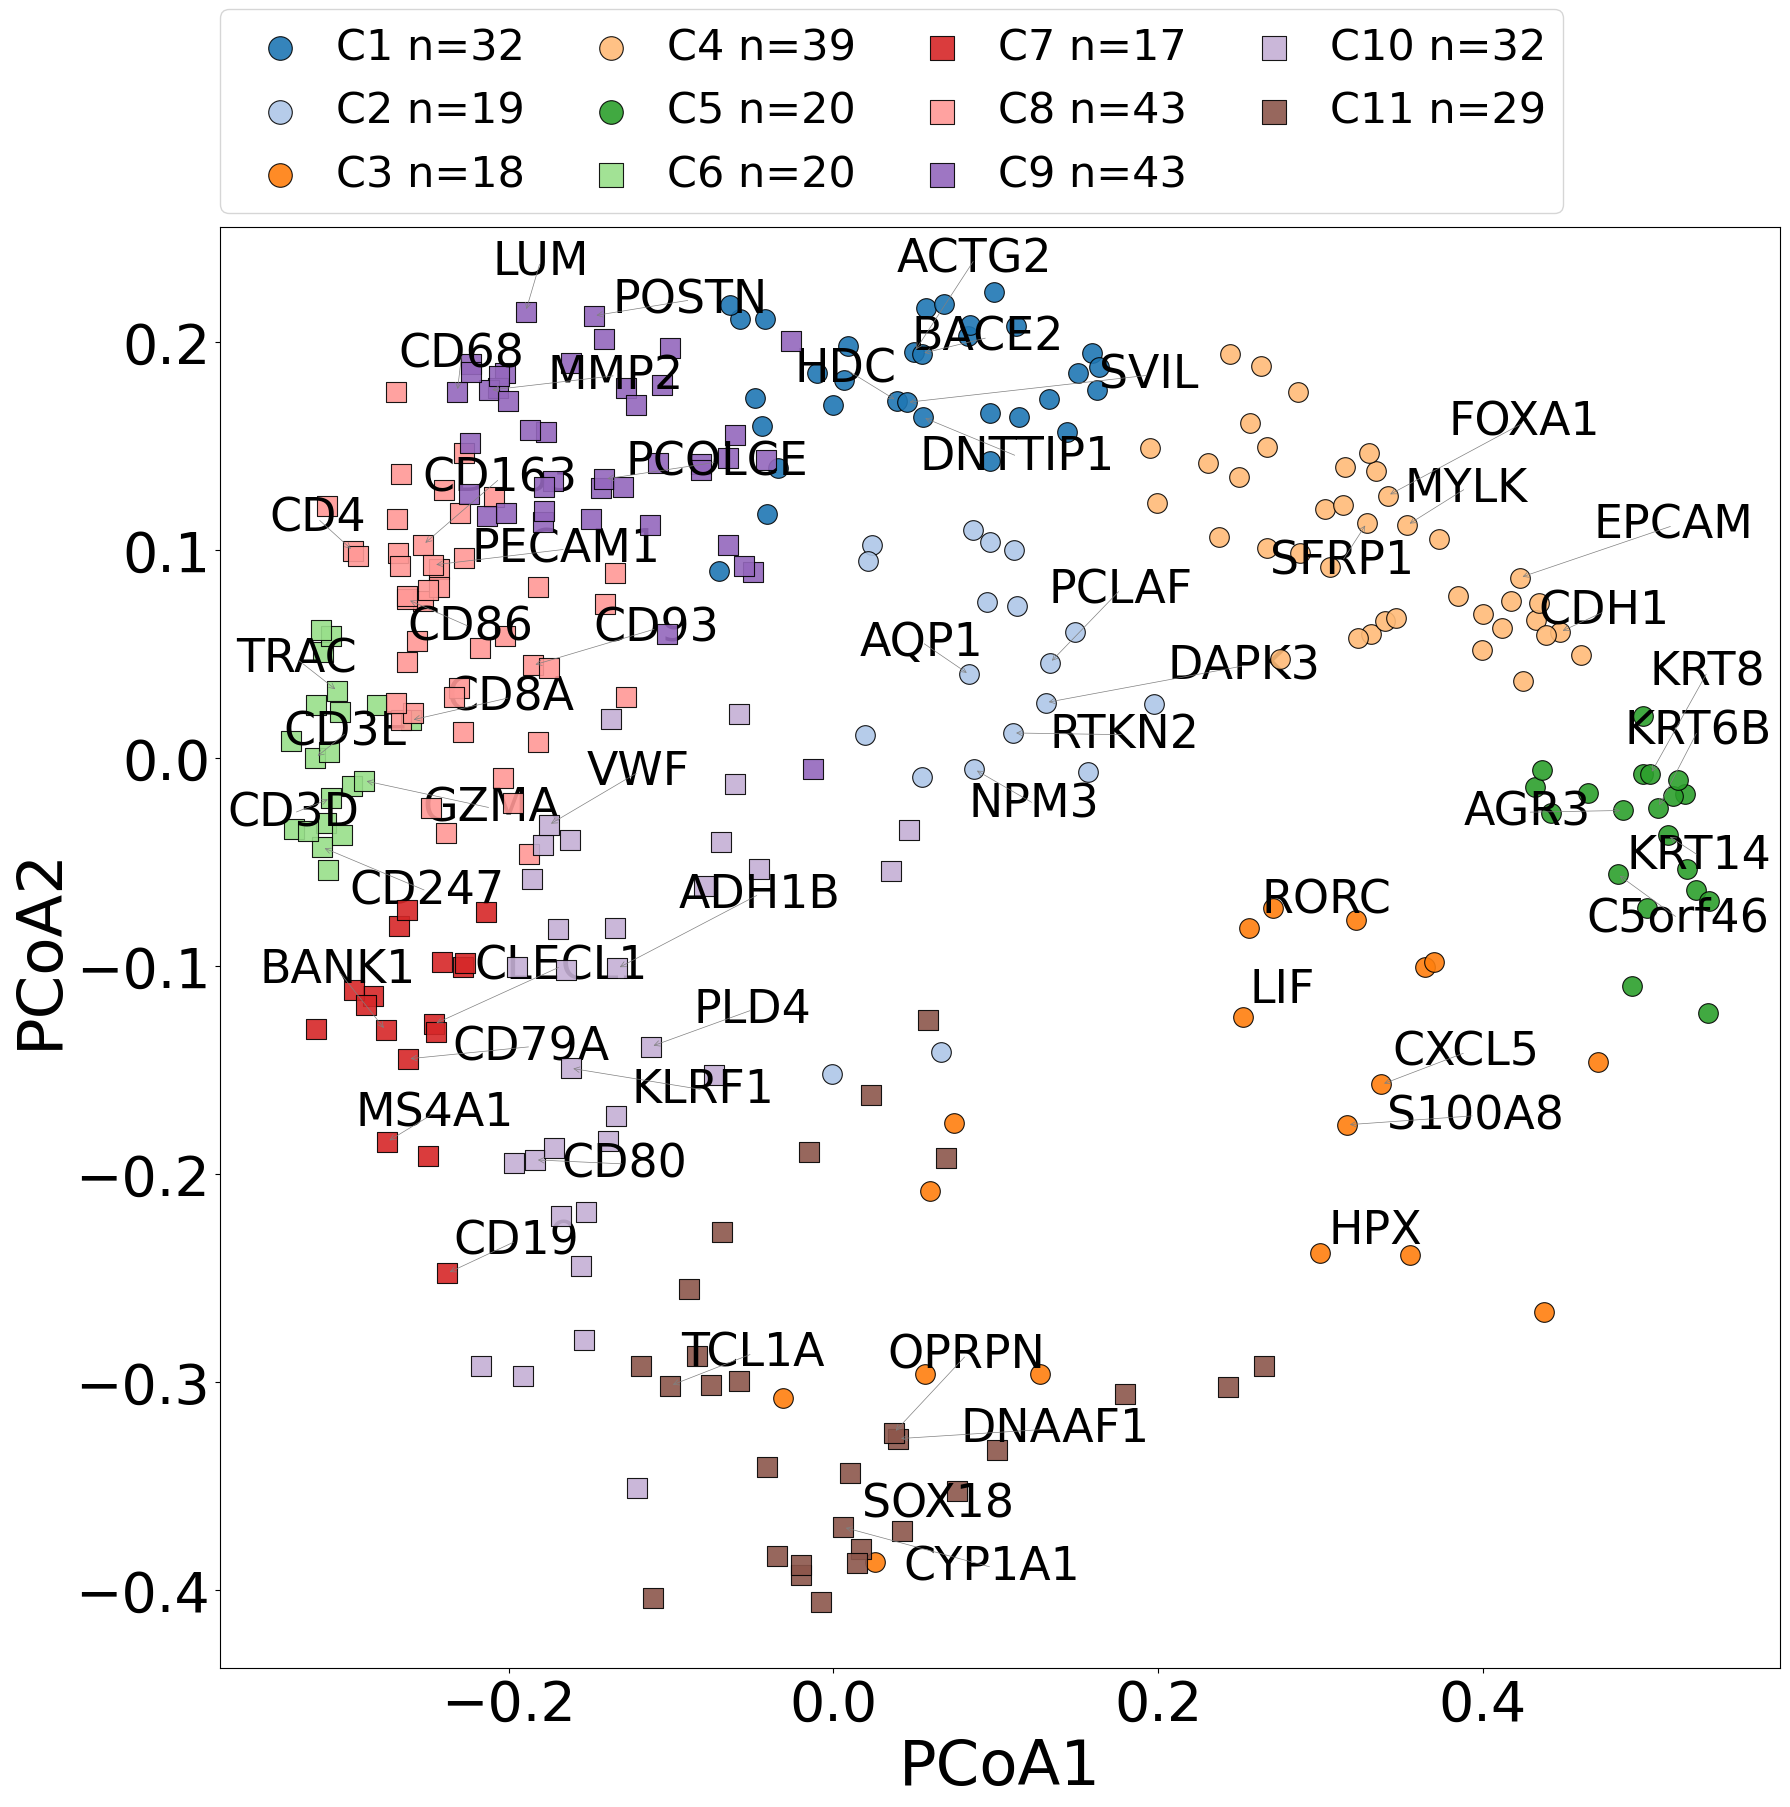

In [5]:
scomv.plot_gene_clusters(gene_clusters)
plt.show()

`gene_clusters.labels` (gene → C1, …; "-" = unclassified) and `gene_clusters.gene_sets` ({cluster: genes}) can be
used elsewhere, e.g. `scomv.plot_pgi_ranking(pgi, cluster=gene_clusters.labels)` or as signatures in
`scomv.signature_polar_enrichment(gene_pipe, gene_clusters.gene_sets, ...)`.

## 3. Where each cluster is: mean polar histogram and presence map

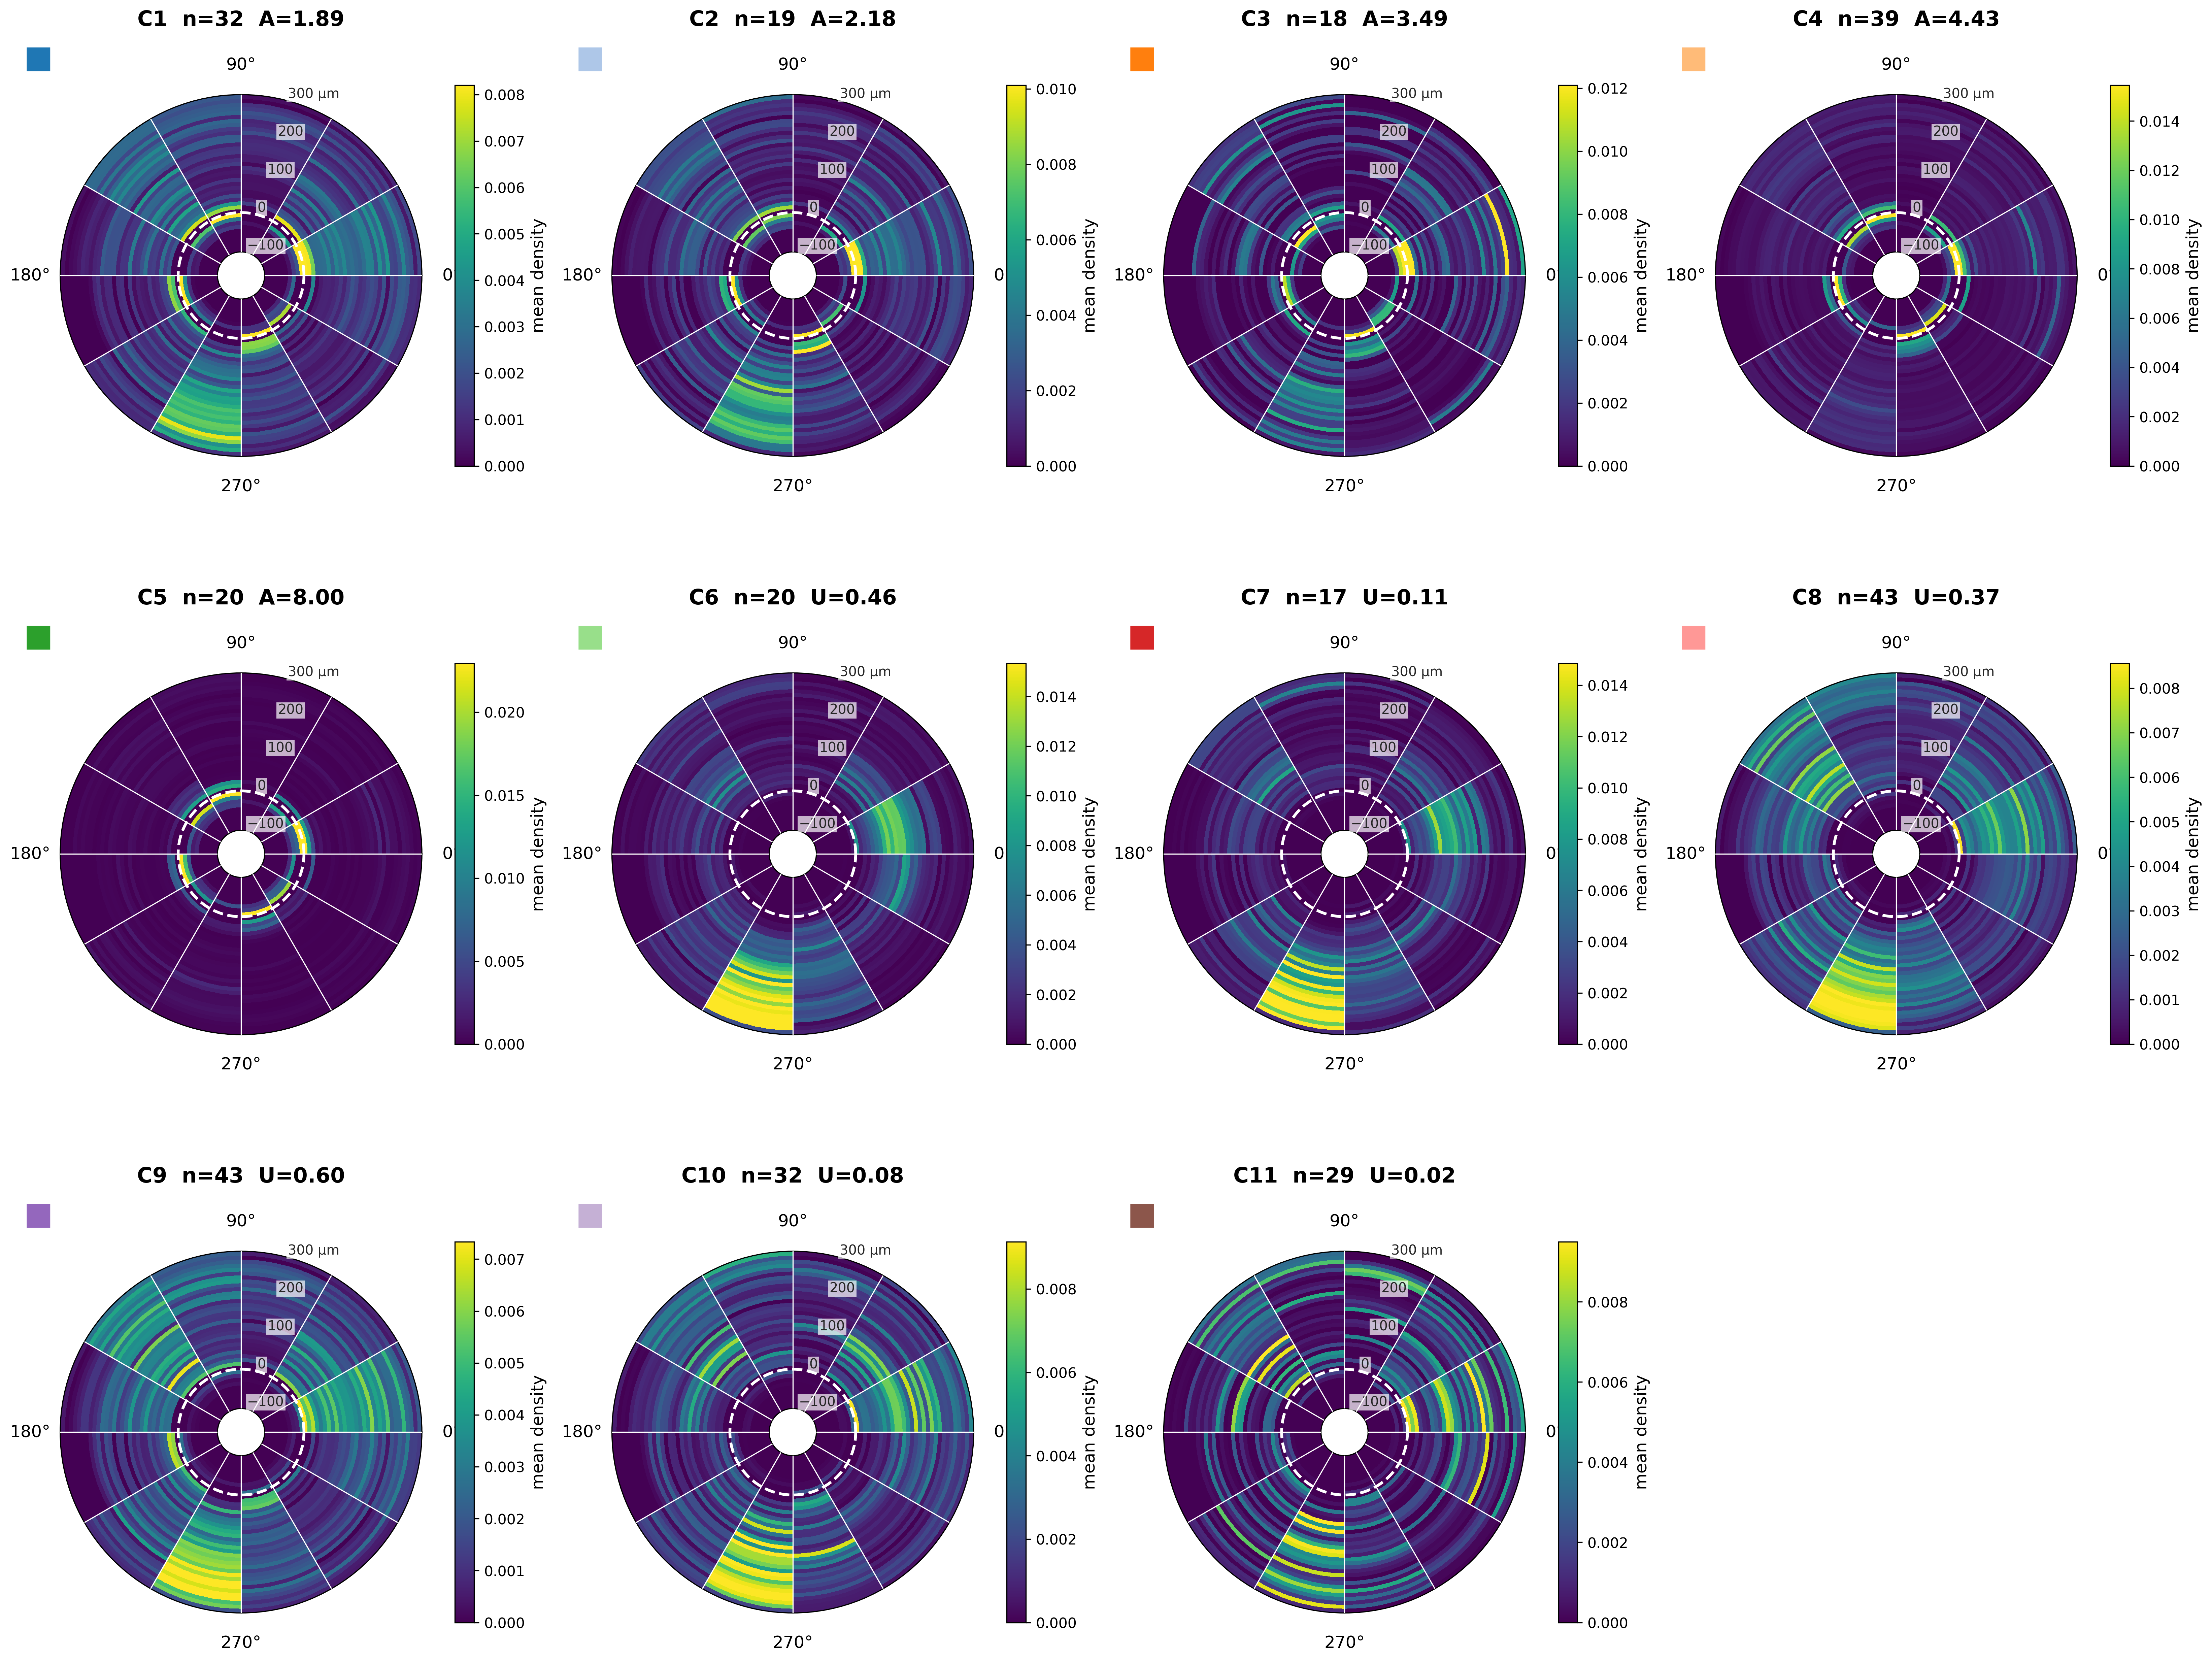

In [6]:
maps = scomv.cluster_mean_maps(gene_pipe, gene_clusters)
scomv.plot_cluster_mean_polar(maps)
plt.show()

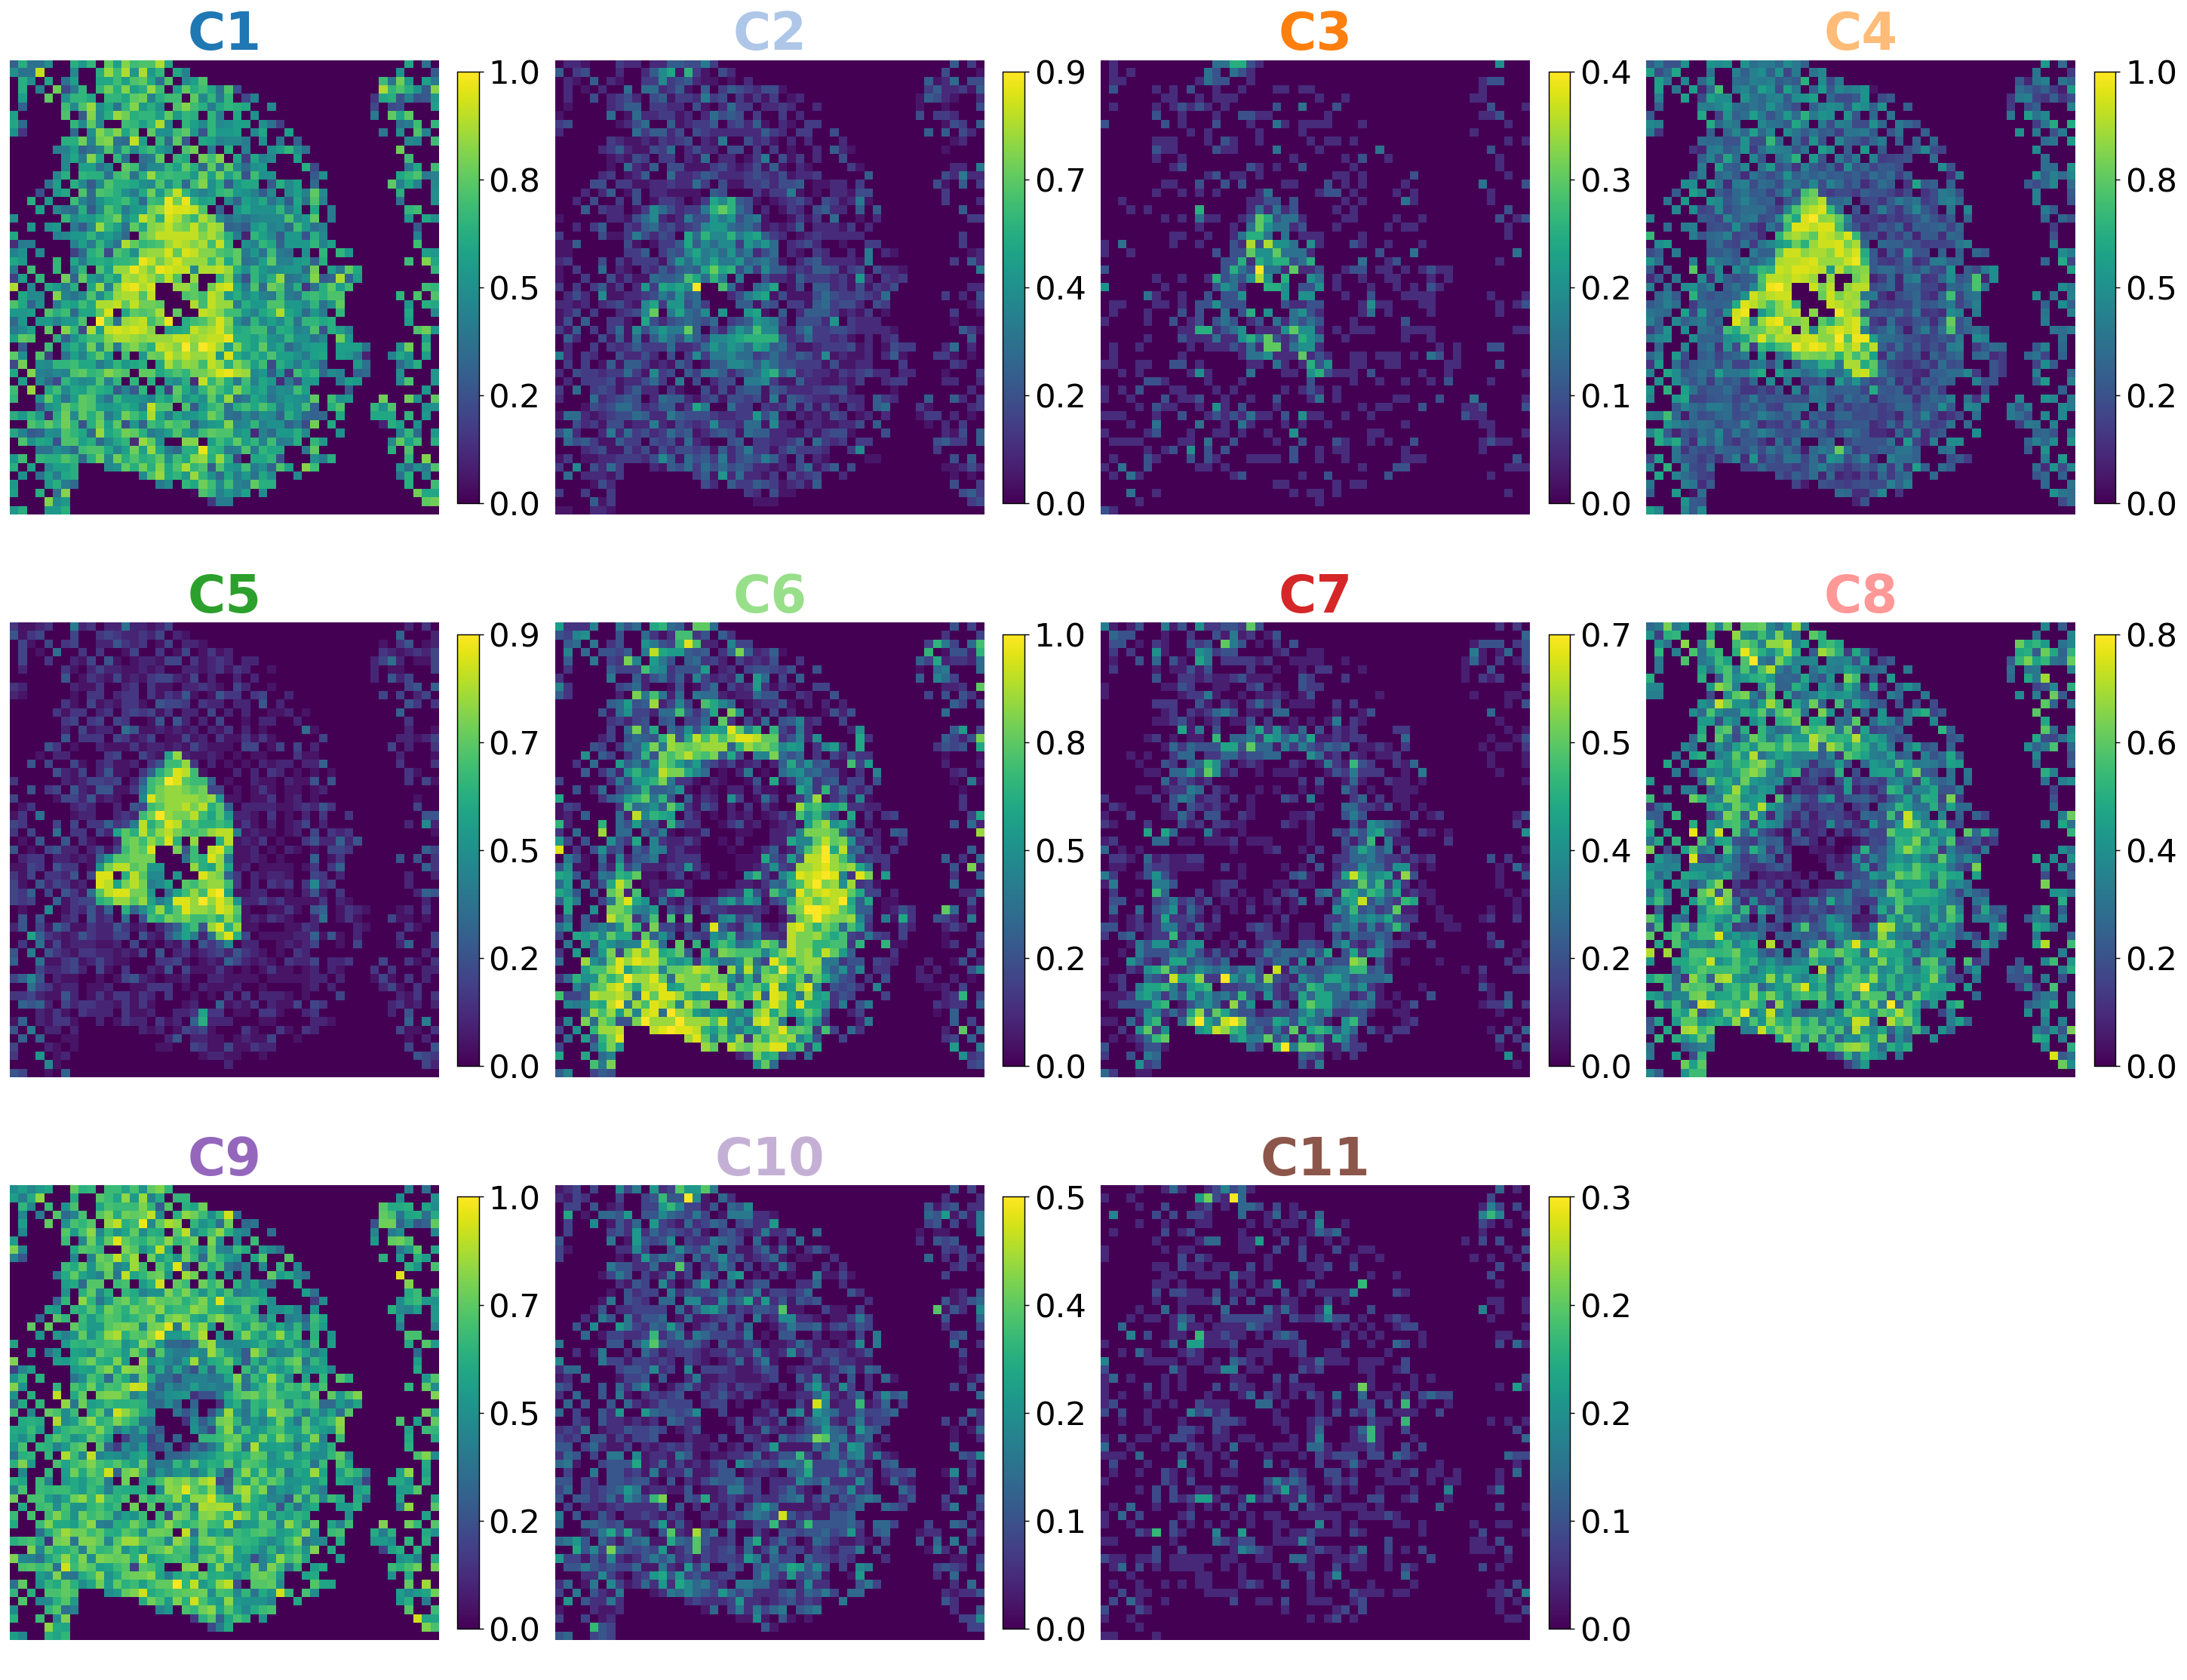

In [7]:
scomv.plot_cluster_presence(maps)
plt.show()

## 4. GO enrichment per cluster (background = the panel genes; needs network)

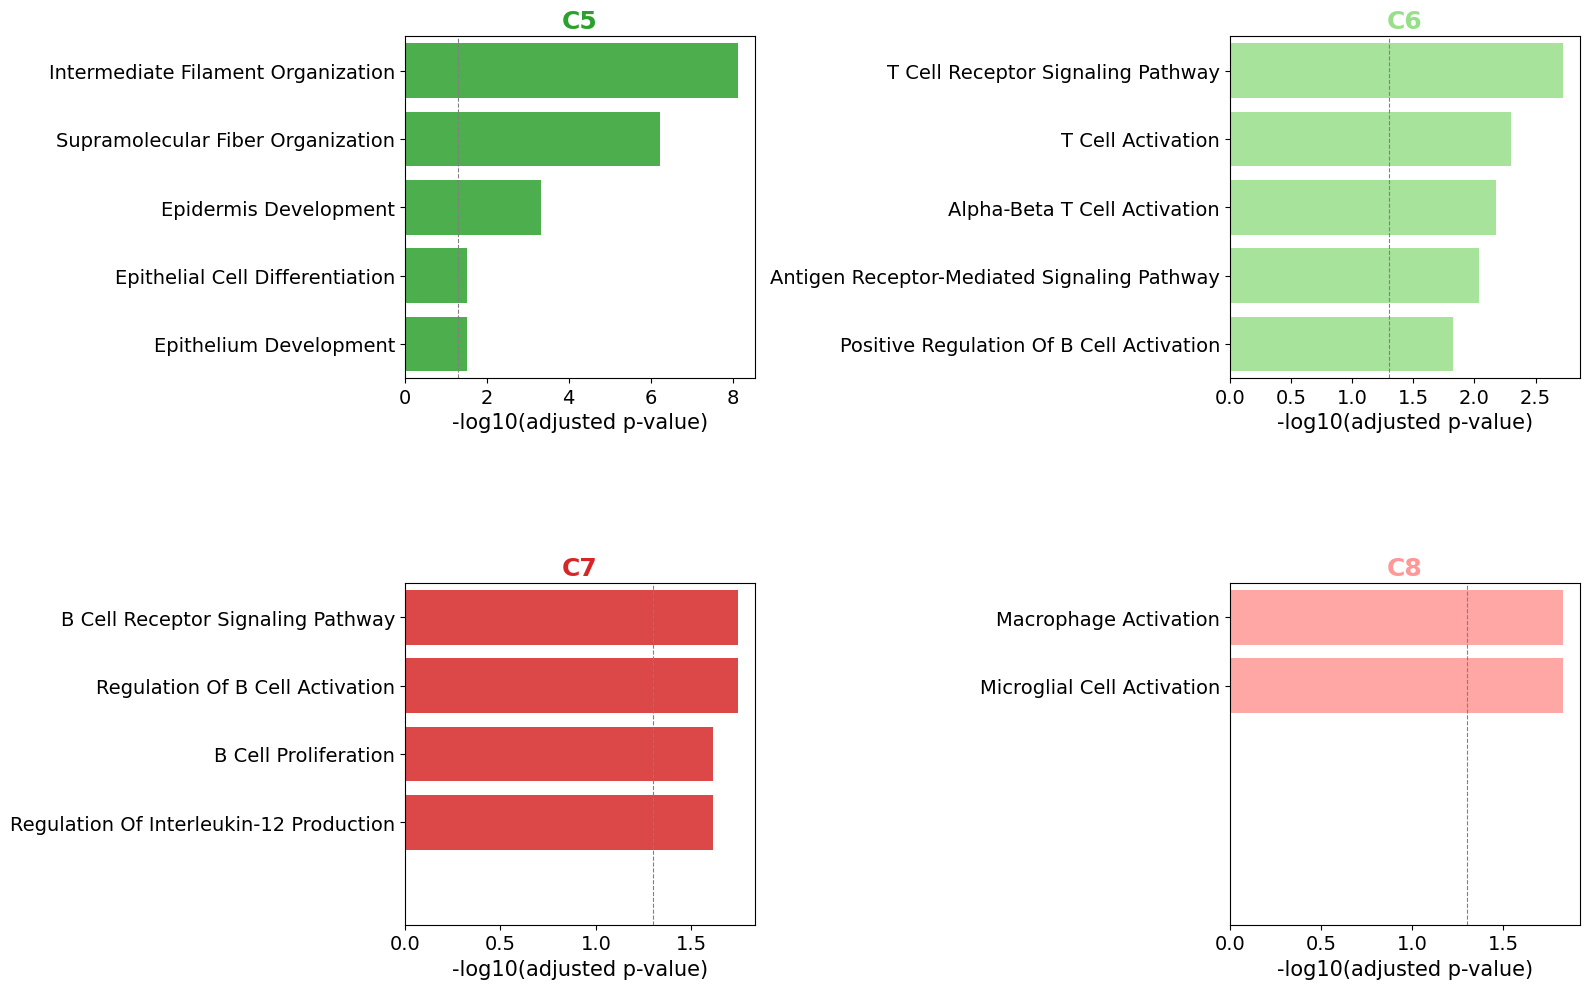

{'C1': 0,
 'C2': 0,
 'C3': 0,
 'C4': 0,
 'C5': 5,
 'C6': 7,
 'C7': 4,
 'C8': 2,
 'C9': 0,
 'C10': 0,
 'C11': 0}

In [8]:
go = scomv.cluster_enrichment(gene_clusters, top_n=5, n_cols=2)
plt.show()
{k: len(v) for k, v in go.items()}